# Assignemnt 3: ANN analysis

## Problem statement:
Finding the stored vectors closest to a query is the core step of dense retrieval. Doing it exactly means comparing the query against every vector, which gets too slow at scale. Approximate nearest neighbour (ANN) indexes are much faster, at the price of sometimes missing a true neighbour. In this assignment you will measure that trade-off yourself. You will benchmark three popular index types, HNSW, IVF-Flat and IVF-PQ, on two public datasets, run one experiment of your choice from a short list, carry out one open-ended experiment of your own on data you generate, and write a short report explaining what you found. We care about careful measurement and clear explanations, not about which index turns out fastest.


## Index Type 3: IVF-PQ
IVF-PQ is an extension of the IVF-Flat index that incorporates product quantization (PQ) to further reduce the memory footprint and speed up the search process. In IVF-PQ, each vector is divided into multiple sub-vectors, and each sub-vector is quantized separately using a codebook. This allows for a more compact representation of the vectors while still enabling efficient nearest neighbor search.

The logic behind IVF-PQ is that by quantizing the vectors, we can store them in a more memory-efficient manner, which is particularly beneficial when dealing with large datasets. The trade-off is that the quantization process introduces some approximation error, which may lead to missing some true nearest neighbors. Quantization can also affect the accuracy of the search, as the distance between quantized vectors may not perfectly reflect the distance between the original vectors.

The implementation of IVF-PQ typically involves the following steps:
1. **Training**: Use k-means clustering to partition the dataset into a specified number of clusters (Voronoi cells). Each cluster is represented by its centroid. Additionally, train a product quantizer on the sub-vectors to create codebooks for quantization. The quantizer is a set of codebooks that map sub-vectors to their quantized representations. Sub-vectors examples are: 
   - For a vector of dimension 128, we can divide it into 4 sub-vectors of dimension 32 each.
   - Each sub-vector is then quantized using a codebook that maps the sub-vector to a quantized representation.
Codebooks are like dictionaries that map sub-vectors to their quantized representations. For example, if we have a codebook with 256 entries, each sub-vector can be represented by an index into the codebook, which requires only 8 bits (1 byte) of storage.
2. **Indexing**: For each vector in the dataset, determine which centroid it is closest to and store it in the corresponding inverted list for that centroid. Additionally, quantize each sub-vector using the trained product quantizer and store the quantized representations in the inverted lists.
3. **Querying**: Given a query vector, find the closest centroids and retrieve the vectors in their inverted lists. Then, perform a linear search within those lists to find the nearest neighbors. The query vector is also quantized using the trained product quantizer, and the search is performed on the quantized representations of the vectors in the inverted lists.

## Measurement protocol (identical for all three indexes)

The same rules as in the IVF-Flat notebook are used, implemented once in `ann_utils.py`.

| Item | Rule used |
|---|---|
| Quality | **recall@10**, tie-aware, against the FAISS exact reference (distances recomputed from the original float vectors, so quantisation error in the index's own distances cannot flatter the score) |
| Speed | **queries per second, one query per `search()` call, one thread**, 3 repeats, **median** |
| Sweep | `nprobe` is increased until recall reaches about 0.99, **or until recall stops improving**. The second condition matters for IVF-PQ, which can have a recall ceiling that more probing cannot lift |
| Recall vs timing | recall on all 10,000 queries (one batched call); timing on the first 500 queries |
| Baseline | exact FAISS search measured with the same single-query, single-thread protocol |

As before, **building** uses all CPU threads (k-means and encoding 1M vectors single-threaded would take very long), so build times are reported with the thread count.

In [1]:
"""
This cell imports the shared helpers (ann_utils.py), sets the experiment configuration, loads both datasets with their exact reference results and measures the exact-search baseline with the single-query, single-thread protocol. No index is built yet.
"""

import gc
import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ann_utils import (K, DATASETS, MAX_THREADS, Evaluator, faiss_metric, make_flat, build_record,
                       run_sweep, set_nprobe, coarse_centroids, exact_baseline_single_thread,
                       best_at_recall, qps_table, build_table, plot_tradeoff, save_df)

# ---- experiment configuration -------------------------------------------------------------
N_TIME_Q = 500        # queries timed per repeat (the first 500 test queries)
REPS = 3              # repeats per timing; the median QPS is reported
STOP_RECALL = 0.99    # stop a sweep once recall reaches this
SEED = 1234
NPROBE_GRID = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024]
PQ_TRAIN_N = 200_000  # vectors used to train the PQ codebooks (FAISS needs at most 256 x 256 = 65k)

NLIST_BASE, NLIST_LARGE = 1024, 4096
NBITS = 8             # 256 codewords per sub-vector: one byte per sub-vector
# M = number of sub-vectors = bytes per code. It must divide the dimension (128 for SIFT, 100 for GloVe).
M_SMALL = {"sift": 8,  "glove": 10}     # 16 / 10 dimensions per sub-vector
M_BASE  = {"sift": 16, "glove": 20}     # 8 / 5 dimensions per sub-vector
M_LARGE = {"sift": 32, "glove": 50}     # 4 / 2 dimensions per sub-vector

# ---- data, reference and exact baseline ---------------------------------------------------
EVAL = {name: Evaluator(name) for name in DATASETS}
BASELINE = {name: exact_baseline_single_thread(EVAL[name]) for name in DATASETS}

RESULTS, BUILDS = [], []
PQ_INDEXES = {}       # small PQ indexes are kept so that Try 6 can add re-ranking on top of Try 2

rows = []
for name, ev in EVAL.items():
    rows.append({"dataset": name, "metric": ev.metric, "N": f"{ev.n:,}", "dim": ev.d,
                 "reference": ev.ref_source, "exact bytes/vector": 4 * ev.d,
                 "exact QPS (1 query, 1 thread)": round(BASELINE[name]["qps"], 1),
                 "M small/base/large": f"{M_SMALL[name]}/{M_BASE[name]}/{M_LARGE[name]}"})
print(f"FAISS {faiss.__version__} | threads available for building: {MAX_THREADS} | timing: 1 thread")
print(pd.DataFrame(rows).to_string(index=False))

FAISS 1.15.1 | threads available for building: 20 | timing: 1 thread
dataset  metric         N  dim                    reference  exact bytes/vector  exact QPS (1 query, 1 thread) M small/base/large
   sift      l2 1,000,000  128 faiss exact (data/processed)                 512                           29.7            8/16/32
  glove angular 1,183,514  100 faiss exact (data/processed)                 400                           32.6           10/20/50


## What IVF-PQ is made of, and what each part costs

IVF-PQ is IVF-Flat with the stored vectors **compressed**. Splitting it into components:

| Component | Knob | What it controls | What it costs |
|---|---|---|---|
| **Coarse quantizer** | `nlist`, `nprobe` | which cells are searched (exactly as in IVF-Flat) | centroid scan per query, as before |
| **Residual encoding** | `by_residual` | whether PQ encodes the vector itself or its difference from the cell centroid | nothing at query time except how look-up tables are built (see below) |
| **Sub-quantizers** | `M` | the vector is cut into `M` pieces, each replaced by the id of its nearest codeword. `M` is also the **number of bytes per code** | compression `4d / M`; more `M` means smaller error but more bytes and more look-ups per vector |
| **Codebook size** | `nbits` | codewords per piece (`2^nbits`; 8 gives 256) | accuracy per piece against training time and table size |
| **Asymmetric distance (ADC) scan** | automatic | the query is kept exact; for each piece a table of distances to all 256 codewords is built, then a stored vector's distance is the sum of `M` table look-ups | table-building cost per query (per probed cell when residuals are used), then very cheap, memory-light scanning |
| **Re-ranking** (optional) | `k_factor` | re-score a longer shortlist with the exact vectors | needs the full vectors in memory again |

Two properties drive all the results below.

1. **Memory and scan speed.** An IVF-Flat vector costs `4d + 8` bytes (520 for SIFT). An IVF-PQ vector costs `M + 8` bytes (24 for SIFT at `M = 16`, about 21x less), and the scan reads that much memory and does `M` look-ups instead of `d` multiply-adds. The 8-byte id becomes a large share of the total at small `M`.
2. **Approximation error.** Distances are computed from compressed codes, so the ranking inside a probed cell is only approximately right. A true neighbour can be ranked below non-neighbours *even if its cell is probed*. This produces a **recall ceiling** that no amount of extra `nprobe` removes, which is the failure mode the assignment asks about.

**How the experiments are controlled.** Training the coarse k-means takes a large share of the build time, and it would also make settings incomparable if each run produced a slightly different partition. So the coarse quantizer is trained **once per dataset and `nlist`**, and every PQ setting reuses exactly the same cells. A difference between two Tries is then caused by the PQ part only (the build time reported for each index still includes the shared k-means time).

In [2]:
"""
This cell defines the helpers used by every Try. get_coarse trains (once) and caches the coarse k-means centroids, build_ivfpq builds an IVF-PQ index on top of those centroids, run_try_pq builds and sweeps it for each dataset and stores the build statistics and sweep points, and run_try_refine adds exact re-ranking on top of an existing IVF-PQ index (used in Try 6).
"""

COARSE = {}   # (dataset, nlist) -> (centroids, training seconds)

def get_coarse(ev, nlist):
    key = (ev.name, nlist)
    if key not in COARSE:
        print(f"[{ev.name}] training coarse quantizer (k-means, nlist={nlist}) - done once and reused ...")
        COARSE[key] = coarse_centroids(ev, nlist, niter=25, spherical=False, seed=SEED)
        print(f"[{ev.name}] coarse k-means took {COARSE[key][1]:.1f} s")
    return COARSE[key]


def build_ivfpq(ev, nlist, M, nbits=NBITS, by_residual=True):
    centroids, coarse_s = get_coarse(ev, nlist)
    quantizer = make_flat(ev.d, ev.metric)
    quantizer.add(centroids)                    # pre-filled quantizer: FAISS skips coarse training
    index = faiss.IndexIVFPQ(quantizer, ev.d, nlist, M, nbits, faiss_metric(ev.metric))
    index.by_residual = by_residual
    sample = ev.train[np.random.default_rng(SEED).choice(ev.n, min(PQ_TRAIN_N, ev.n), replace=False)]
    t0 = time.perf_counter(); index.train(sample);  pq_train_s = time.perf_counter() - t0   # PQ codebooks
    t0 = time.perf_counter(); index.add(ev.train);  add_s = time.perf_counter() - t0        # assign + encode
    return index, coarse_s + pq_train_s, add_s


def report_sweep(df, name, ev):
    for t in (0.90, 0.95):
        b = best_at_recall(df, t)
        msg = (f"nprobe={int(b['param'])} (recall {b['recall']:.4f}, {b['qps']:.0f} QPS)" if b is not None
               else f"NOT reached (max recall {df['recall'].max():.4f})")
        print(f"[{name}] recall >= {t}: {msg}")


def run_try_pq(try_name, nlist, M_by_ds, by_residual=True, keep=False):
    print("=" * 100)
    print(try_name)
    for name in DATASETS:
        ev, M = EVAL[name], M_by_ds[name]
        print(f"\n[{name}] building IVF-PQ: nlist={nlist}, M={M} ({ev.d // M} dims per sub-vector), "
              f"nbits={NBITS}, by_residual={by_residual}")
        index, train_s, add_s = build_ivfpq(ev, nlist, M, NBITS, by_residual)
        rec = build_record(ev, index, name, "IVF-PQ", try_name,
                           f"nlist={nlist}, M={M}, nbits={NBITS}, by_residual={by_residual}", train_s, add_s)
        code_bytes = M * NBITS / 8
        rec.update(nlist=nlist, M=M, code_bytes=code_bytes, compression_x=4 * ev.d / code_bytes,
                   is_refine=False)
        BUILDS.append(rec)
        print(f"[{name}] build: train {train_s:.1f} s (incl. shared k-means) + add {add_s:.1f} s | "
              f"size {rec['size_mb']:.1f} MB = {rec['bytes_per_vector']:.1f} bytes/vector "
              f"(code {code_bytes:.0f} B, compression of the raw vector {rec['compression_x']:.0f}x)")

        grid = [p for p in NPROBE_GRID if p <= nlist]
        df = run_sweep(index, ev, set_nprobe, grid, n_time_q=N_TIME_Q, reps=REPS,
                       stop_recall=STOP_RECALL, param_name="nprobe", label=f"[{name}] ")
        df.insert(0, "try", try_name); df.insert(0, "dataset", name); df.insert(0, "index", "IVF-PQ")
        df["is_refine"] = False
        RESULTS.append(df)
        report_sweep(df, name, ev)
        if keep:
            PQ_INDEXES[(name, try_name)] = index
        else:
            del index
        gc.collect()


def run_try_refine(try_name, base_try, k_factors):
    print("=" * 100)
    print(try_name)
    for name in DATASETS:
        ev = EVAL[name]
        base = PQ_INDEXES[(name, base_try)]
        b0 = [b for b in BUILDS if b["dataset"] == name and b["try"] == base_try][0]
        print(f"\n[{name}] adding exact re-ranking (full vectors) on top of '{base_try}'")
        t0 = time.perf_counter()
        flat = make_flat(ev.d, ev.metric); flat.add(ev.train)       # exact copy used only for re-scoring
        refine_add_s = time.perf_counter() - t0
        size_rec = None
        for kf in k_factors:
            label = f"{try_name} (k_factor={kf})"
            rf = faiss.IndexRefine(base, flat)
            rf.k_factor = kf
            rf.own_fields = False
            if size_rec is None:
                size_rec = build_record(ev, rf, name, "IVF-PQ+rerank", label, "", 0, 0)
            rec = dict(size_rec, **{"try": label},
                       build=f"{b0['build']} + exact re-rank, k_factor={kf}",
                       train_s=b0["train_s"], add_s=b0["add_s"] + refine_add_s,
                       build_s=b0["build_s"] + refine_add_s, nlist=b0["nlist"], M=b0["M"],
                       code_bytes=b0["code_bytes"], compression_x=4 * ev.d / size_rec["bytes_per_vector"],
                       is_refine=True)
            BUILDS.append(rec)
            print(f"[{name}] k_factor={kf}: size {rec['size_mb']:.0f} MB = {rec['bytes_per_vector']:.0f} bytes/vector "
                  f"(the full vectors are stored again)")
            grid = [p for p in NPROBE_GRID if p <= b0["nlist"]]
            df = run_sweep(rf, ev, set_nprobe, grid, n_time_q=N_TIME_Q, reps=REPS,
                           stop_recall=STOP_RECALL, param_name="nprobe", label=f"[{name}] k_factor={kf} ")
            df.insert(0, "try", label); df.insert(0, "dataset", name); df.insert(0, "index", "IVF-PQ+rerank")
            df["is_refine"] = True
            RESULTS.append(df)
            report_sweep(df, name, ev)
        del flat
        gc.collect()

print("helpers defined")

helpers defined


## Tries 1 to 3: how many bytes per vector? (`M` = 8 / 16 / 32 on SIFT, 10 / 20 / 50 on GloVe)

These three Tries vary only **`M`**, the number of sub-vectors, with `nlist = 1024`, `nbits = 8`, residual encoding, and the same coarse cells. `M` is the central knob of product quantization: it sets the code size (bytes per vector) and therefore the compression, and it sets how coarsely each piece of the vector is represented.

**Decision.**

| | SIFT (d = 128) | GloVe (d = 100) |
|---|---|---|
| Try 1, small | `M = 8` (16 dims/piece, 8 B code, 64x) | `M = 10` (10 dims/piece, 10 B code, 40x) |
| Try 2, **base** | `M = 16` (8 dims/piece, 16 B code, 32x) | `M = 20` (5 dims/piece, 20 B code, 20x) |
| Try 3, large | `M = 32` (4 dims/piece, 32 B code, 16x) | `M = 50` (2 dims/piece, 50 B code, 8x) |

**Reasoning.**
- `M` has to divide `d`, so the two datasets need different values; 100 is not divisible by 8, 16 or 32, which is why GloVe uses 10, 20 and 50 instead of a copy of the SIFT values.
- Each step doubles (or more) the code size, so the effect of bytes-per-vector on recall is visible at three clearly separated points rather than a smear of neighbouring values.
- Going from `M` to `2M` roughly halves the number of dimensions each 256-word codebook has to cover, so quantisation error shrinks sharply.

**Alternatives not chosen.**
- *`M = 64` for SIFT (2 dims/piece):* would show the high-accuracy end, but 64 B codes are already one eighth of the raw vector and the extra lookups slow scanning. GloVe's `M = 50` already shows that end of the curve.
- *`nbits = 4` (16 codewords, the SIMD "fast scan" variant):* much faster scanning, but accuracy per piece is far lower, it needs a different index class (`IndexIVFPQFastScan`) that only pays off with batching, and it is a different algorithm from the IVF-PQ of the assignment.
- *`nbits = 12` or `16`:* 4096 to 65536 codewords per piece make codebook training and the per-query tables 16x to 256x larger and break byte alignment of codes; they trade the speed advantage that motivates PQ for accuracy that re-ranking can provide more cheaply (Try 6).
- *Varying `M` and `nlist` together:* would mix two effects, so `nlist` stays fixed here.

**Hypothesis.** Recall reached at large `nprobe` (the ceiling) rises with `M` and bytes per vector, while QPS at equal recall falls (more look-ups per vector). With `M` small the sweep should flatten well below 0.95 on at least one dataset. Differences between SIFT and GloVe come partly from the number of dimensions per piece.

In [3]:
"""
Try 1: small codes (M = 8 for SIFT, M = 10 for GloVe), nlist = 1024.
"""
run_try_pq("Try 1: small codes (M=8 sift | M=10 glove)", NLIST_BASE, M_SMALL)

Try 1: small codes (M=8 sift | M=10 glove)

[sift] building IVF-PQ: nlist=1024, M=8 (16 dims per sub-vector), nbits=8, by_residual=True
[sift] training coarse quantizer (k-means, nlist=1024) - done once and reused ...
[sift] coarse k-means took 17.1 s
[sift] build: train 23.7 s (incl. shared k-means) + add 5.2 s | size 16.7 MB = 16.7 bytes/vector (code 8 B, compression of the raw vector 64x)
  [sift] nprobe=1     recall@10=0.2440 |  30294.0 QPS (  0.033 ms/q) | compared  0.11% of db
  [sift] nprobe=2     recall@10=0.3070 |  24280.6 QPS (  0.041 ms/q) | compared  0.21% of db
  [sift] nprobe=3     recall@10=0.3337 |  21550.5 QPS (  0.046 ms/q) | compared  0.32% of db
  [sift] nprobe=4     recall@10=0.3487 |  10708.3 QPS (  0.093 ms/q) | compared  0.43% of db
  [sift] nprobe=6     recall@10=0.3646 |   9577.2 QPS (  0.104 ms/q) | compared  0.64% of db
  [sift] nprobe=8     recall@10=0.3724 |  10737.2 QPS (  0.093 ms/q) | compared  0.85% of db
  [sift] nprobe=12    recall@10=0.3798 |   8372

In [4]:
"""
Try 2: base codes (M = 16 for SIFT, M = 20 for GloVe), nlist = 1024. The index is kept in memory (it is small) so Try 6 can add re-ranking on top of it.
"""
BASE_TRY = "Try 2: base codes (M=16 sift | M=20 glove)"
run_try_pq(BASE_TRY, NLIST_BASE, M_BASE, keep=True)

Try 2: base codes (M=16 sift | M=20 glove)

[sift] building IVF-PQ: nlist=1024, M=16 (8 dims per sub-vector), nbits=8, by_residual=True
[sift] build: train 30.1 s (incl. shared k-means) + add 4.0 s | size 24.7 MB = 24.7 bytes/vector (code 16 B, compression of the raw vector 32x)
  [sift] nprobe=1     recall@10=0.3107 |  20224.3 QPS (  0.049 ms/q) | compared  0.11% of db
  [sift] nprobe=2     recall@10=0.4120 |  18670.7 QPS (  0.054 ms/q) | compared  0.21% of db
  [sift] nprobe=3     recall@10=0.4617 |  11049.7 QPS (  0.091 ms/q) | compared  0.32% of db
  [sift] nprobe=4     recall@10=0.4909 |  10113.3 QPS (  0.099 ms/q) | compared  0.43% of db
  [sift] nprobe=6     recall@10=0.5220 |   8638.9 QPS (  0.116 ms/q) | compared  0.64% of db
  [sift] nprobe=8     recall@10=0.5387 |   6978.5 QPS (  0.143 ms/q) | compared  0.85% of db
  [sift] nprobe=12    recall@10=0.5547 |   4777.0 QPS (  0.209 ms/q) | compared  1.27% of db
  [sift] nprobe=16    recall@10=0.5622 |   3450.1 QPS (  0.290 ms/q) 

In [5]:
"""
Try 3: large codes (M = 32 for SIFT, M = 50 for GloVe), nlist = 1024.
"""
run_try_pq("Try 3: large codes (M=32 sift | M=50 glove)", NLIST_BASE, M_LARGE)

Try 3: large codes (M=32 sift | M=50 glove)

[sift] building IVF-PQ: nlist=1024, M=32 (4 dims per sub-vector), nbits=8, by_residual=True
[sift] build: train 41.8 s (incl. shared k-means) + add 5.5 s | size 40.7 MB = 40.7 bytes/vector (code 32 B, compression of the raw vector 16x)
  [sift] nprobe=1     recall@10=0.3487 |   9038.3 QPS (  0.111 ms/q) | compared  0.11% of db
  [sift] nprobe=2     recall@10=0.4827 |   9307.2 QPS (  0.107 ms/q) | compared  0.21% of db
  [sift] nprobe=3     recall@10=0.5526 |   7210.3 QPS (  0.139 ms/q) | compared  0.32% of db
  [sift] nprobe=4     recall@10=0.5961 |   7119.7 QPS (  0.140 ms/q) | compared  0.43% of db
  [sift] nprobe=6     recall@10=0.6443 |   3768.4 QPS (  0.265 ms/q) | compared  0.64% of db
  [sift] nprobe=8     recall@10=0.6709 |   3365.6 QPS (  0.297 ms/q) | compared  0.85% of db
  [sift] nprobe=12    recall@10=0.6975 |   2602.5 QPS (  0.384 ms/q) | compared  1.27% of db
  [sift] nprobe=16    recall@10=0.7111 |   1918.9 QPS (  0.521 ms/q)

## Try 4: encode the vector itself instead of its residual (`by_residual = False`)

**Decision.** Base `M`, `nlist = 1024`, same cells, but PQ now encodes the raw vector `x` instead of the residual `x - centroid`.

**Reasoning.** The default (and base) encodes residuals because a residual has much smaller spread than the full vector: the cell centroid has already explained the coarse position, so the 256 codewords of each piece only have to describe the remaining detail. This Try measures how much that choice is worth, with everything else identical. It also exposes a second-order effect: with residuals, the distance tables depend on which cell is probed, so they are built once **per probed cell**; without residuals one table per query serves all cells.

**Alternatives not chosen.**
- *Keeping `by_residual = True` and varying nothing:* that is the base, already run.
- *Running it for `M` small and large as well:* the conclusion would not change and it would triple the runtime; the base `M` is enough to isolate the effect.

**Hypothesis.** Lower recall ceiling at the same bytes per vector, because the codewords must now cover the whole vector range. Per-query table cost should drop at high `nprobe`, which may offset some of the speed lost to the lower accuracy; the time split in the analysis shows whether it does.

In [6]:
"""
Try 4: base codes and cells, but PQ encodes the raw vector instead of the residual.
"""
run_try_pq("Try 4: base codes, by_residual=False", NLIST_BASE, M_BASE, by_residual=False)

Try 4: base codes, by_residual=False

[sift] building IVF-PQ: nlist=1024, M=16 (8 dims per sub-vector), nbits=8, by_residual=False
[sift] build: train 29.7 s (incl. shared k-means) + add 4.0 s | size 24.7 MB = 24.7 bytes/vector (code 16 B, compression of the raw vector 32x)
  [sift] nprobe=1     recall@10=0.2977 |  22466.9 QPS (  0.045 ms/q) | compared  0.11% of db
  [sift] nprobe=2     recall@10=0.3935 |  10494.7 QPS (  0.095 ms/q) | compared  0.21% of db
  [sift] nprobe=3     recall@10=0.4405 |  11650.5 QPS (  0.086 ms/q) | compared  0.32% of db
  [sift] nprobe=4     recall@10=0.4679 |  10635.6 QPS (  0.094 ms/q) | compared  0.43% of db
  [sift] nprobe=6     recall@10=0.4985 |   6214.8 QPS (  0.161 ms/q) | compared  0.64% of db
  [sift] nprobe=8     recall@10=0.5154 |   5479.7 QPS (  0.182 ms/q) | compared  0.85% of db
  [sift] nprobe=12    recall@10=0.5306 |   3852.8 QPS (  0.260 ms/q) | compared  1.27% of db
  [sift] nprobe=16    recall@10=0.5381 |   3456.6 QPS (  0.289 ms/q) | com

## Try 5: finer cells for the same code size (`nlist = 4096`)

**Decision.** Base `M`, residual encoding, but `nlist = 4096` instead of 1024.

**Reasoning.** In IVF-PQ `nlist` does two jobs. As in IVF-Flat it makes the search more selective. But with residual encoding it also makes the *residuals smaller*: a vector is closer to its centroid when there are more centroids, so PQ has less to describe and the quantisation error falls without spending a single extra byte per vector. This Try tests that interaction.

**Alternatives not chosen.**
- *`nlist = 256`:* the coarse end was already studied with IVF-Flat, and here it would produce larger residuals and higher error, which is easy to predict.
- *`nlist = 16384`:* see the IVF-Flat notebook; the training time and the centroid cost per query are too high for this protocol.
- *Larger `nlist` combined with larger `M`:* two knobs at once.

**Hypothesis.** A higher recall ceiling than Try 2 at the same code size, at the price of a larger fixed centroid cost per query and a longer build. The cost of precomputed distance tables also grows with `nlist` (for L2 data, `nlist x M x 256` floats).

In [7]:
"""
Try 5: base codes, nlist = 4096 (a new coarse k-means is trained once and cached).
"""
run_try_pq("Try 5: base codes, nlist=4096", NLIST_LARGE, M_BASE)

Try 5: base codes, nlist=4096

[sift] building IVF-PQ: nlist=4096, M=16 (8 dims per sub-vector), nbits=8, by_residual=True
[sift] training coarse quantizer (k-means, nlist=4096) - done once and reused ...
[sift] coarse k-means took 261.1 s
[sift] build: train 274.5 s (incl. shared k-means) + add 12.6 s | size 26.3 MB = 26.3 bytes/vector (code 16 B, compression of the raw vector 32x)
  [sift] nprobe=1     recall@10=0.2586 |   9029.9 QPS (  0.111 ms/q) | compared  0.03% of db
  [sift] nprobe=2     recall@10=0.3596 |   7245.4 QPS (  0.138 ms/q) | compared  0.05% of db
  [sift] nprobe=3     recall@10=0.4160 |   6652.8 QPS (  0.150 ms/q) | compared  0.08% of db
  [sift] nprobe=4     recall@10=0.4508 |   6707.5 QPS (  0.149 ms/q) | compared  0.11% of db
  [sift] nprobe=6     recall@10=0.4929 |   6954.3 QPS (  0.144 ms/q) | compared  0.16% of db
  [sift] nprobe=8     recall@10=0.5180 |   7731.1 QPS (  0.129 ms/q) | compared  0.22% of db
  [sift] nprobe=12    recall@10=0.5451 |   5619.2 QPS ( 

## Try 6: exact re-ranking of the shortlist (`IndexRefine`, `k_factor` = 4 and 16)

**Decision.** Take the base IVF-PQ index from Try 2, keep a second copy of the full vectors, and let the search work in two stages: IVF-PQ returns the best `k_factor x 10` candidates by *approximate* distance, and those candidates are then re-scored with their exact vectors and cut to 10.

**Reasoning.** This tests the explanation for the recall ceiling directly. If the ceiling is caused by approximate distances ordering true neighbours too low, then widening the shortlist and fixing the order with exact distances should lift it, without probing more cells. The cost is memory: the index again holds `4d` bytes per vector, so it gives up PQ's main benefit. It is therefore a *diagnostic and a tuning option*, not a free improvement, and it is kept out of the main report curve (see below).

**Alternatives not chosen.**
- *`k_factor = 1`:* no change at all, the shortlist is just the answer.
- *`k_factor = 64` or more:* more exact re-scoring work per query with rapidly diminishing returns; 4 and 16 bracket the useful range.
- *`IndexIVFPQR` (a second, finer PQ for refinement):* keeps memory low, but is a different structure with its own parameters. It belongs to the improvement experiments, not to the base characterisation.
- *OPQ rotation (`OPQ16,IVF1024,PQ16`):* balances variance between sub-vectors and improves PQ accuracy without extra memory. It needs a separate training step and a per-query matrix multiply, so it is also left for the improvement part.

**Hypothesis.** The ceiling disappears or rises sharply, and the larger `k_factor` helps more but costs more time per query. If recall climbs towards 1.0 only after re-ranking, that confirms the ceiling comes from distance approximation and not from missed cells.

In [8]:
"""
Try 6: add exact re-ranking (IndexRefine) on top of the Try 2 index with k_factor 4 and 16. These runs are tagged is_refine and kept out of the main report curve.
"""
run_try_refine("Try 6: base codes + exact re-ranking", BASE_TRY, k_factors=(4, 16))

Try 6: base codes + exact re-ranking

[sift] adding exact re-ranking (full vectors) on top of 'Try 2: base codes (M=16 sift | M=20 glove)'
[sift] k_factor=4: size 537 MB = 537 bytes/vector (the full vectors are stored again)
  [sift] k_factor=4 nprobe=1     recall@10=0.3710 |  13645.4 QPS (  0.073 ms/q) | compared  0.11% of db
  [sift] k_factor=4 nprobe=2     recall@10=0.5322 |  10876.5 QPS (  0.092 ms/q) | compared  0.21% of db
  [sift] k_factor=4 nprobe=3     recall@10=0.6235 |  10491.9 QPS (  0.095 ms/q) | compared  0.32% of db
  [sift] k_factor=4 nprobe=4     recall@10=0.6836 |   7963.7 QPS (  0.126 ms/q) | compared  0.43% of db
  [sift] k_factor=4 nprobe=6     recall@10=0.7554 |   7153.1 QPS (  0.140 ms/q) | compared  0.64% of db
  [sift] k_factor=4 nprobe=8     recall@10=0.7973 |   4632.4 QPS (  0.216 ms/q) | compared  0.85% of db
  [sift] k_factor=4 nprobe=12    recall@10=0.8416 |   3688.8 QPS (  0.271 ms/q) | compared  1.27% of db
  [sift] k_factor=4 nprobe=16    recall@10=0.86

## Comparing the Tries: which component bought what?

For each dataset the table shows, per Try, the **recall ceiling** (the highest recall the sweep reached), the bytes per vector, and, where the target was reached, the `nprobe`, the share of the database compared and the QPS at recall 0.90 and 0.95. A second table splits the per-query time at recall 0.95 (or at the best recall reached if 0.95 is never reached) into the centroid step and the list scan.

How to read it:
- *Same `nlist`, different ceiling* means the PQ part (`M`, residual encoding) limits recall, not the probing.
- *Ceiling reached at small `nprobe` and flat afterwards* is the signature of approximation error rather than missed cells.
- *Ceiling changes only when `nlist` changes* shows the interaction between cell size and residual size.
- Tries 1 to 5 are the pure IVF-PQ index; Try 6 stores full vectors again and is shown for diagnosis only.

In [9]:
"""
This cell compares all Tries: recall ceiling, bytes per vector, nprobe / scanned share / QPS at recall 0.90 and 0.95, and the split of query time between the centroid step and the list scan.
"""
RES = pd.concat(RESULTS, ignore_index=True)
BLD = pd.DataFrame(BUILDS)

for ds in DATASETS:
    n = EVAL[ds].n
    rows, split = [], []
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        b = BLD[(BLD["dataset"] == ds) & (BLD["try"] == tr)].iloc[0]
        row = {"try": tr, "bytes/vec": round(b["bytes_per_vector"], 1), "ceiling": round(g["recall"].max(), 4),
               "nprobe at ceiling": int(g.loc[g["recall"].idxmax(), "param"])}
        for t in (0.90, 0.95):
            r = best_at_recall(g, t)
            row[f"nprobe@{t}"] = int(r["param"]) if r is not None else None
            row[f"scanned%@{t}"] = round(r["dist_comps_per_query"] / n * 100, 2) if r is not None else None
            row[f"QPS@{t}"] = round(r["qps"], 1) if r is not None else None
        rows.append(row)
        r_ref = best_at_recall(g, 0.95)
        r_ref = g.loc[g["recall"].idxmax()] if r_ref is None else r_ref
        split.append({"try": tr, "at recall": round(r_ref["recall"], 4), "nprobe": int(r_ref["param"]),
                      "centroid step ms": round(r_ref["quantize_ms_per_query"], 3),
                      "list scan ms": round(r_ref["scan_ms_per_query"], 3),
                      "total ms (measured)": round(r_ref["ms_per_query"], 3)})
    print(f"\n===== {ds}: Tries side by side (exact baseline: {BASELINE[ds]['qps']:.1f} QPS, {4 * EVAL[ds].d} bytes/vector) =====")
    print(pd.DataFrame(rows).to_string(index=False))
    print(f"\n----- {ds}: where the time goes (at recall 0.95, or at the ceiling if 0.95 is not reached) -----")
    print(pd.DataFrame(split).to_string(index=False))

print("\n===== build cost =====")
print(BLD[["dataset", "try", "train_s", "add_s", "size_mb", "bytes_per_vector"]].round(1).to_string(index=False))


===== sift: Tries side by side (exact baseline: 29.7 QPS, 512 bytes/vector) =====
                                               try  bytes/vec  ceiling  nprobe at ceiling  nprobe@0.9  scanned%@0.9  QPS@0.9  nprobe@0.95  scanned%@0.95  QPS@0.95
        Try 1: small codes (M=8 sift | M=10 glove)       16.7   0.3860                 48         NaN           NaN      NaN          NaN            NaN       NaN
        Try 2: base codes (M=16 sift | M=20 glove)       24.7   0.5732                 96         NaN           NaN      NaN          NaN            NaN       NaN
       Try 3: large codes (M=32 sift | M=50 glove)       40.7   0.7320                 96         NaN           NaN      NaN          NaN            NaN       NaN
              Try 4: base codes, by_residual=False       24.7   0.5489                 64         NaN           NaN      NaN          NaN            NaN       NaN
                     Try 5: base codes, nlist=4096       26.3   0.5928                192         NaN 

## Report item 1: recall@10 against queries per second

Same layout as in the IVF-Flat notebook: thin lines are the individual build settings, the bold black line is the best trade-off curve, the red star is exact FAISS search (same single-query, single-thread protocol). The main figure uses **only pure IVF-PQ settings (Tries 1 to 5)**, because that is the index the assignment asks for. The second figure adds the re-ranked variants (Try 6) to show what exact re-ranking does to the curve and to the ceiling.

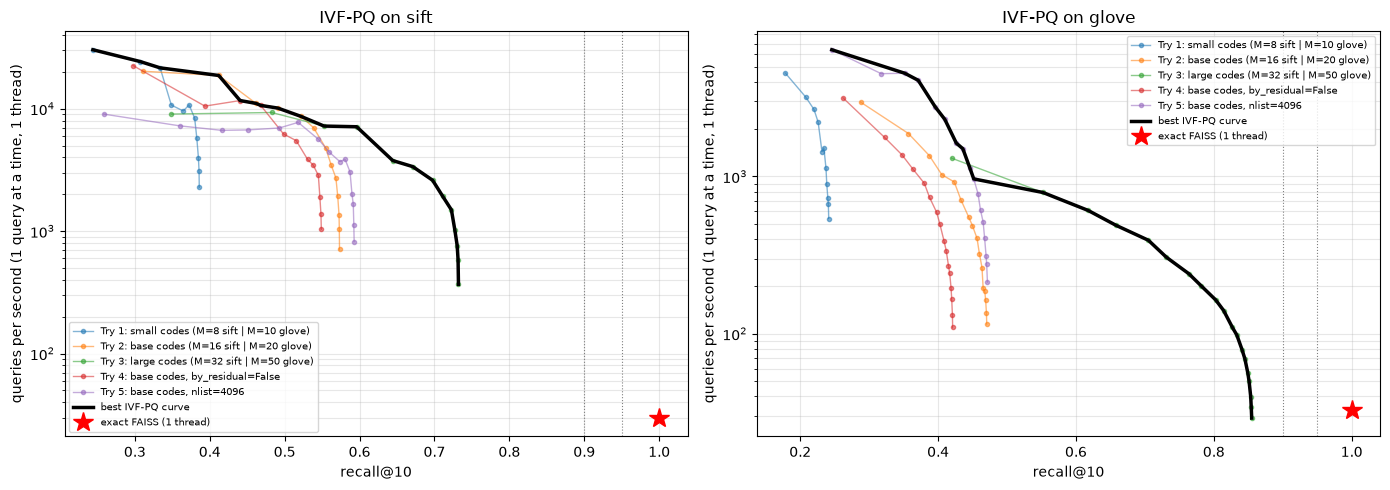

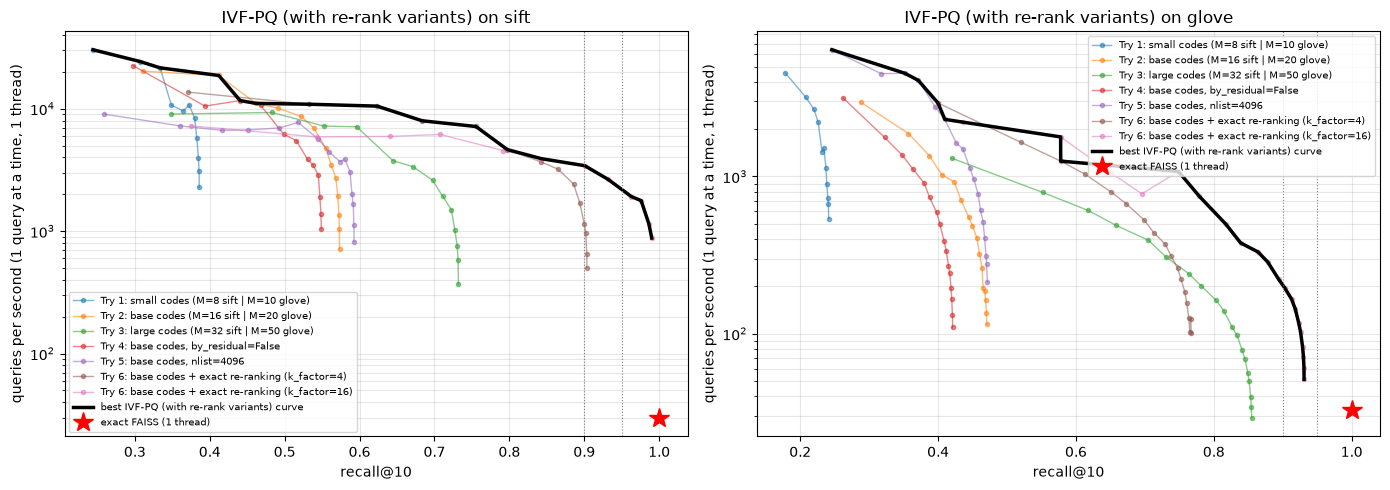

In [10]:
"""
This cell plots recall@10 against QPS for the pure IVF-PQ settings (the curve used in the report) and then again including the re-ranked variants (Try 6) for comparison. Both figures are saved to data/processed/plots.
"""
RES_MAIN = RES[~RES["is_refine"]]
fig = plot_tradeoff(RES_MAIN, BASELINE, "IVF-PQ", "./data/processed/plots/ivfpq_tradeoff.png")
plt.show()

fig = plot_tradeoff(RES, BASELINE, "IVF-PQ (with re-rank variants)", "./data/processed/plots/ivfpq_with_rerank.png")
plt.show()

## Report items 2 and 3: tables at recall 0.90 and 0.95

Both tables use the **pure IVF-PQ settings only** (Tries 1 to 5). If a dataset never reaches a target, the table says so and shows the highest recall that was reached; that is a result, not an error, and it is explained in the next section. Exact search stores `4 x d` bytes per vector (512 for SIFT, 400 for GloVe).

In [11]:
"""
This cell prints the report tables for pure IVF-PQ: QPS at recall 0.90 and 0.95, and build time / index size / bytes per vector for the configuration that reaches recall 0.95.
"""
BLD_MAIN = BLD[~BLD["is_refine"]]
print("QPS at recall 0.90 and 0.95 (best pure IVF-PQ configuration; one query at a time, one thread)")
print(qps_table(RES_MAIN).to_string(index=False))
print("\nexact FAISS baseline QPS:", {k: round(v["qps"], 1) for k, v in BASELINE.items()})

print(f"\nBuild time, index size and bytes per vector at recall 0.95 (build threads: {MAX_THREADS})")
print(build_table(RES_MAIN, BLD_MAIN).to_string(index=False))
print("\nexact search for comparison: bytes per vector =", {k: 4 * EVAL[k].d for k in DATASETS}, "(no build step)")

QPS at recall 0.90 and 0.95 (best pure IVF-PQ configuration; one query at a time, one thread)
dataset  target_recall  qps  recall     setting  param
  glove           0.90  NaN 0.85496 not reached    NaN
  glove           0.95  NaN 0.85496 not reached    NaN
   sift           0.90  NaN 0.73202 not reached    NaN
   sift           0.95  NaN 0.73202 not reached    NaN

exact FAISS baseline QPS: {'sift': 29.7, 'glove': 32.6}

Build time, index size and bytes per vector at recall 0.95 (build threads: 20)
dataset                 setting
  glove recall 0.95 not reached
   sift recall 0.95 not reached

exact search for comparison: bytes per vector = {'sift': 512, 'glove': 400} (no build step)


## Why an index fails to reach high recall: the IVF-PQ case

There are two independent reasons a true neighbour can be missed, and only one of them can be fixed by searching longer.

1. **It is in a cell that was not probed.** This is the same effect as in IVF-Flat; raising `nprobe` fixes it.
2. **It was in a probed cell but its approximate distance ranked it too low.** PQ replaces each stored vector by a small code, so the distance to the query is only approximate, and a true neighbour can score worse than some non-neighbour. Probing more cells does not help; this sets a **recall ceiling** for a given code size.

The two checks below make this concrete for our runs. The first lists the ceiling of every pure IVF-PQ Try and whether 0.95 is reached. The second shows what happens when the exact vectors are used to re-rank the shortlist (Try 6): if the ceiling rises sharply without probing more cells, the missing neighbours were being lost to distance approximation and not to cell selection. The sentence or two for the report can then be written from these numbers: *which settings fail to reach 0.95, what the ceiling is, and what lifts it (more bytes via larger `M`, smaller residuals via larger `nlist`, or exact re-ranking at the cost of memory)*.

In [12]:
"""
This cell prints the recall ceiling of every Try and, for the re-ranked variants, how much of the gap to 1.0 re-ranking recovers compared with the base index at the same nprobe.
"""
for ds in DATASETS:
    print(f"[{ds}]")
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        top = g["recall"].max()
        print(f"  {tr:<58} ceiling recall@10 = {top:.4f} -> reaches 0.95: {'yes' if top >= 0.95 else 'NO'}")

print("\nEffect of exact re-ranking at equal nprobe (base IVF-PQ vs re-ranked):")
for ds in DATASETS:
    g = RES[RES["dataset"] == ds]
    base = g[g["try"] == BASE_TRY].set_index("param")["recall"]
    for tr in [t for t in g["try"].unique() if t.startswith("Try 6")]:
        rr = g[g["try"] == tr].set_index("param")["recall"]
        common = [p for p in base.index if p in rr.index]
        if common:
            p = common[-1]
            print(f"  [{ds}] nprobe={p}: base {base[p]:.4f} -> {tr.split('(')[-1].rstrip(')')} {rr[p]:.4f}")

[sift]
  Try 1: small codes (M=8 sift | M=10 glove)                 ceiling recall@10 = 0.3860 -> reaches 0.95: NO
  Try 2: base codes (M=16 sift | M=20 glove)                 ceiling recall@10 = 0.5732 -> reaches 0.95: NO
  Try 3: large codes (M=32 sift | M=50 glove)                ceiling recall@10 = 0.7320 -> reaches 0.95: NO
  Try 4: base codes, by_residual=False                       ceiling recall@10 = 0.5489 -> reaches 0.95: NO
  Try 5: base codes, nlist=4096                              ceiling recall@10 = 0.5927 -> reaches 0.95: NO
  Try 6: base codes + exact re-ranking (k_factor=4)          ceiling recall@10 = 0.9035 -> reaches 0.95: NO
  Try 6: base codes + exact re-ranking (k_factor=16)         ceiling recall@10 = 0.9901 -> reaches 0.95: yes
[glove]
  Try 1: small codes (M=8 sift | M=10 glove)                 ceiling recall@10 = 0.2413 -> reaches 0.95: NO
  Try 2: base codes (M=16 sift | M=20 glove)                 ceiling recall@10 = 0.4706 -> reaches 0.95: NO
  Try 3: lar

## Saving the results

The sweep points and build records are saved for the final cross-index comparison and the tweak experiments.

In [13]:
"""
This cell saves all sweep points and build records of this notebook as csv files in data/processed.
"""
print("saved:", save_df(RES, "results_ivfpq.csv"))
print("saved:", save_df(BLD, "builds_ivfpq.csv"))
print(f"{len(RES)} sweep points over {RES['try'].nunique()} Tries, {len(BLD)} index builds")

saved: ./data/processed/results_ivfpq.csv
saved: ./data/processed/builds_ivfpq.csv
207 sweep points over 7 Tries, 14 index builds


## Observations (fill in after running)

Use these prompts to turn the output above into the explanations the report asks for.

- **Code size** (Tries 1 to 3): how do the ceiling, QPS and bytes per vector change with `M`? Which `M` is the smallest to reach 0.95 on each dataset, if any?
- **Residuals** (Try 4): how much recall is lost by encoding raw vectors? Did the cheaper table step compensate in QPS?
- **Cell size** (Try 5): did finer cells raise the ceiling without more bytes per vector, and what did it cost in build time and per-query centroid cost?
- **Re-ranking** (Try 6): how far does exact re-ranking lift the ceiling, and what does it do to bytes per vector? Is it still smaller than IVF-Flat's 520 / 420 bytes?
- **Where the time goes**: at high recall, is the query time dominated by building distance tables or by scanning codes?
- **Against IVF-Flat**: at recall 0.90 and 0.95, is IVF-PQ faster than IVF-Flat in this single-thread setting, and what is the saving in memory?